# Model results

Displays the metrics and figures written by `src/evaluate_models.py`. The modelling code lives in `src/forecast_model/`; this notebook only reads its outputs, so the two can't disagree.

- **open** cutoff: 11 AM ET the day before, one hour after Kalshi opens (main result)
- **midnight** cutoff: just before the measured day (fresher forecasts)

Set `RERUN = True` to regenerate everything (about a minute).

In [2]:
import json
import subprocess
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src' / 'evaluate_models.py').exists())
OUTPUTS = ROOT / 'outputs'
CUTOFFS = ['open', 'midnight']
METRICS = ['high', 'low']
RERUN = False

if RERUN or not all((OUTPUTS / c / 'metrics.json').exists() for c in CUTOFFS):
    subprocess.run([sys.executable, str(ROOT / 'src' / 'evaluate_models.py')], cwd=ROOT, check=True)

reports = {c: json.loads((OUTPUTS / c / 'metrics.json').read_text()) for c in CUTOFFS}
for c, r in reports.items():
    print(f"{c:9} {r['description']}  |  sources: {', '.join(r['sources'])}")

open      11 AM ET the day before (1 h after Kalshi opens)  |  sources: mos00, gfs_day2, icon_day2, gem_day2, ecmwf_day2
midnight  Midnight before the measured day  |  sources: mos, gfs_day1, hrrr_day1, icon_day1, gem_day1, ecmwf_day1


## Headline: test-period MAE (°F), lower is better

Test period is 2026, scored once. HRRR is blank at the open cutoff because it doesn't forecast that far ahead.

In [3]:
def table(cutoff, metric):
    return pd.DataFrame(reports[cutoff][metric]['table']).set_index('method')

def common_name(method):
    # 'Average of 5 sources' (open) and 'Average of 6 sources' (midnight) share one row.
    return 'Average of sources' if method.startswith('Average of ') else method

mae = pd.concat({(c, m): table(c, m)['mae'].rename(common_name) for c in CUTOFFS for m in METRICS}, axis=1)
mae.columns.names = ['cutoff', 'metric']
mae = mae.sort_values(('open', 'high'))
mae.style.format('{:.2f}', na_rep='—').background_gradient(cmap='RdYlGn_r', axis=0)

In [4]:
SINGLE = {'NWS MOS', 'GFS', 'HRRR', 'ICON', 'GEM', 'ECMWF'}
rows = []
for c in CUTOFFS:
    for m in METRICS:
        t = table(c, m)['mae']
        single = t[t.index.isin(SINGLE)].idxmin()
        ml = t[t.index.str.startswith('ML:')].idxmin()
        rows.append({'cutoff': c, 'metric': m, 'best single source': single, 'single MAE': t[single],
                     'best ML model': ml, 'ML MAE': t[ml],
                     'bias-corrected avg MAE': t['Average, bias-corrected (30d)'],
                     'ML gain vs best single': 1 - t[ml] / t[single]})
pd.DataFrame(rows).style.format({'single MAE': '{:.2f}', 'ML MAE': '{:.2f}',
                                 'bias-corrected avg MAE': '{:.2f}', 'ML gain vs best single': '{:.0%}'})

,cutoff,metric,best single source,single MAE,best ML model,ML MAE,bias-corrected avg MAE,ML gain vs best single
0,open,high,NWS MOS,2.43,ML: Ridge regression,1.96,1.99,19%
1,open,low,NWS MOS,2.16,ML: Ridge regression,1.59,1.63,26%
2,midnight,high,NWS MOS,2.30,ML: Ridge regression,1.69,1.74,27%
3,midnight,low,NWS MOS,2.10,ML: Gradient boosting,1.48,1.51,30%


## Full error tables

`bias` is forecast minus observed (positive = too warm). `exact` and `within_1f` round every prediction to whole degrees, the way Kalshi settles.

In [5]:
FMT = {'mae': '{:.2f}', 'rmse': '{:.2f}', 'bias': '{:+.2f}', 'exact': '{:.0%}', 'within_1f': '{:.0%}'}
for c in CUTOFFS:
    for m in METRICS:
        t = table(c, m)
        display(Markdown(f'**{c} cutoff, daily {m}** ({t.n.iloc[0]:,} station-days, same days for every method)'))
        display(t.drop(columns='n').style.format(FMT))

**open cutoff, daily high** (2,365 station-days, same days for every method)

,mae,rmse,bias,exact,within_1f
method,,,,,
ML: Ridge regression,1.96,2.63,-0.10,17%,50%
ML: Gradient boosting,1.98,2.67,-0.09,18%,50%
"Average, bias-corrected (30d)",1.99,2.69,+0.02,18%,48%
Average of 5 sources,2.27,2.96,-0.59,15%,41%
NWS MOS,2.43,3.38,+0.08,17%,43%
ICON,2.71,3.65,-0.70,13%,37%
GFS,3.25,4.48,+0.55,12%,33%
GEM,3.42,4.41,-2.40,9%,28%
ECMWF,3.72,4.91,-0.49,8%,26%


**open cutoff, daily low** (2,365 station-days, same days for every method)

,mae,rmse,bias,exact,within_1f
method,,,,,
ML: Ridge regression,1.59,2.15,-0.03,22%,59%
ML: Gradient boosting,1.61,2.15,+0.04,22%,58%
"Average, bias-corrected (30d)",1.63,2.21,-0.00,22%,58%
Average of 5 sources,1.74,2.40,+0.01,21%,57%
NWS MOS,2.16,3.09,+0.79,17%,47%
ICON,2.29,3.03,+0.07,16%,42%
ECMWF,2.31,3.31,-0.46,17%,46%
GEM,3.21,4.35,-2.08,13%,34%
GFS,3.34,4.38,+1.74,10%,31%


**midnight cutoff, daily high** (2,290 station-days, same days for every method)

,mae,rmse,bias,exact,within_1f
method,,,,,
ML: Ridge regression,1.69,2.25,-0.08,20%,56%
ML: Gradient boosting,1.71,2.30,-0.06,22%,55%
"Average, bias-corrected (30d)",1.74,2.31,+0.02,21%,53%
Average of 6 sources,2.03,2.60,-0.66,15%,45%
NWS MOS,2.30,3.20,+0.07,16%,45%
ICON,2.46,3.32,-0.83,15%,42%
HRRR,2.59,3.38,-1.01,13%,37%
GFS,3.01,4.18,+0.62,13%,36%
GEM,3.27,4.26,-2.37,9%,28%


**midnight cutoff, daily low** (2,290 station-days, same days for every method)

,mae,rmse,bias,exact,within_1f
method,,,,,
ML: Gradient boosting,1.48,1.95,+0.14,22%,61%
ML: Ridge regression,1.48,2.02,-0.01,24%,62%
"Average, bias-corrected (30d)",1.51,2.05,+0.01,25%,61%
Average of 6 sources,1.63,2.25,-0.32,22%,58%
NWS MOS,2.10,3.07,+0.84,18%,49%
ICON,2.12,2.82,+0.08,16%,46%
ECMWF,2.14,3.06,-0.42,18%,48%
HRRR,2.82,3.67,-2.21,12%,33%
GEM,3.07,4.22,-2.00,14%,37%


## MAE by city (°F)

Coloured within each city column: green is the best method for that city.

In [6]:
for c in CUTOFFS:
    for m in METRICS:
        per_city = pd.DataFrame(reports[c][m]['per_city']).T
        per_city = per_city.loc[per_city.mean(axis=1).sort_values().index]
        display(Markdown(f'**{c} cutoff, daily {m}**'))
        display(per_city.style.format('{:.2f}').background_gradient(cmap='RdYlGn_r', axis=0))

**open cutoff, daily high**

,Boston,Chicago,Dallas,Los Angeles,Miami,New York,San Francisco,Seattle
ML: Ridge regression,2.29,2.10,1.98,2.05,1.31,1.96,2.20,1.80
ML: Gradient boosting,2.43,2.10,2.05,1.91,1.25,2.00,2.29,1.81
"Average, bias-corrected (30d)",2.29,2.03,1.97,2.21,1.24,1.86,2.50,1.84
Average of 5 sources,2.63,2.27,2.06,2.48,1.76,2.39,2.52,2.02
NWS MOS,2.84,3.22,2.30,2.31,1.28,2.43,2.71,2.31
ICON,2.76,2.72,2.16,2.97,1.76,2.35,4.04,2.90
GFS,3.71,2.76,2.85,2.66,1.63,3.71,5.58,3.05
GEM,3.75,3.73,3.14,2.49,2.48,3.36,5.09,3.32
ECMWF,3.12,3.13,3.04,7.29,4.00,3.52,2.85,2.77
Persistence (2 days earlier),8.77,9.08,6.39,4.50,3.29,7.83,5.22,6.28


**open cutoff, daily low**

,Boston,Chicago,Dallas,Los Angeles,Miami,New York,San Francisco,Seattle
ML: Ridge regression,1.78,1.87,1.66,1.16,1.63,2.02,1.33,1.27
ML: Gradient boosting,1.74,2.01,1.80,1.21,1.64,1.93,1.29,1.28
"Average, bias-corrected (30d)",1.81,1.94,1.71,1.17,1.69,2.13,1.34,1.27
Average of 5 sources,1.92,2.03,1.87,1.21,1.67,2.41,1.48,1.31
NWS MOS,2.37,3.05,2.35,1.47,2.25,2.32,1.67,1.76
ICON,2.25,2.24,2.11,2.35,2.55,2.36,2.70,1.77
ECMWF,2.82,2.51,2.56,2.08,1.65,3.51,1.74,1.61
GEM,2.74,3.19,3.16,5.78,2.19,4.43,1.41,2.76
GFS,2.51,2.78,4.47,4.54,3.99,2.79,3.28,2.35
Persistence (2 days earlier),5.49,6.16,5.84,2.63,3.64,6.24,2.49,3.59


**midnight cutoff, daily high**

,Boston,Chicago,Dallas,Los Angeles,Miami,New York,San Francisco,Seattle
ML: Ridge regression,2.01,1.68,1.67,1.69,1.17,1.75,1.93,1.61
ML: Gradient boosting,2.08,1.79,1.80,1.60,1.11,1.75,1.95,1.62
"Average, bias-corrected (30d)",2.02,1.65,1.67,1.85,1.10,1.71,2.25,1.65
Average of 6 sources,2.33,1.89,1.94,2.03,1.70,2.17,2.23,1.94
NWS MOS,2.70,2.85,2.26,2.11,1.32,2.43,2.55,2.20
ICON,2.26,2.24,1.92,2.85,1.68,1.99,3.82,2.90
HRRR,2.56,2.64,2.37,2.40,2.35,2.90,2.99,2.53
GFS,3.30,2.24,2.44,2.31,1.49,3.68,5.65,2.92
GEM,3.47,3.57,2.91,2.41,2.46,3.13,5.03,3.16
ECMWF,2.81,2.68,2.78,7.08,3.80,3.22,2.62,2.53


**midnight cutoff, daily low**

,Boston,Chicago,Dallas,Los Angeles,Miami,New York,San Francisco,Seattle
ML: Gradient boosting,1.70,1.76,1.53,1.17,1.53,1.75,1.24,1.15
ML: Ridge regression,1.81,1.56,1.42,1.10,1.57,1.95,1.27,1.17
"Average, bias-corrected (30d)",1.86,1.66,1.46,1.05,1.60,2.00,1.29,1.16
Average of 6 sources,1.98,1.71,1.55,1.40,1.57,2.30,1.32,1.25
NWS MOS,2.47,3.00,2.21,1.48,2.13,2.36,1.52,1.67
ICON,1.97,2.07,1.89,2.17,2.40,2.14,2.64,1.70
ECMWF,2.67,2.04,2.41,2.04,1.56,3.22,1.72,1.48
HRRR,3.21,2.46,1.79,3.55,3.00,4.07,2.50,1.96
GEM,2.79,3.05,2.84,5.76,2.11,4.02,1.32,2.65
GFS,2.49,2.58,4.16,4.45,4.04,2.80,3.34,2.21


## Model selection and uncertainty

Each family's settings are chosen on the validation period (Jul–Dec 2025), then refit on train + validation. `sigma` is the fixed per-city uncertainty currently used to turn a forecast into Kalshi bracket probabilities; the planned Model 3 replaces it with a per-day estimate.

In [7]:
rows = [{'cutoff': c, 'metric': m, 'family': fam, 'candidate': cand, 'validation MAE': v,
         'chosen': cand == reports[c][m]['chosen'][fam]}
        for c in CUTOFFS for m in METRICS
        for fam, cands in reports[c][m]['val_mae'].items() for cand, v in cands.items()]
selection = pd.DataFrame(rows)
display(selection.pivot_table(index=['family', 'candidate'], columns=['cutoff', 'metric'], values='validation MAE')
        .style.format('{:.3f}').highlight_min(axis=0, color='#cfe8cf'))
display(pd.DataFrame({c: reports[c]['high']['sizes'] for c in CUTOFFS}).rename_axis('rows (daily high)'))

,open,midnight
rows (daily high),,
train,4096,4096
val,1472,1472
test,2374,2374


In [8]:
sigma = pd.concat({(c, fam): pd.Series(s) for c in CUTOFFS for fam, s in reports[c]['high']['sigma'].items()}, axis=1)
sigma.columns.names = ['cutoff', 'family']
sigma.style.format('{:.2f}').set_caption('Per-city sigma, daily high (°F)')

## Figures

Saved by `src/forecast_model/plots.py`. The `eda_*` charts use train + validation data only.

### open cutoff

`eda_bias_by_city.png`

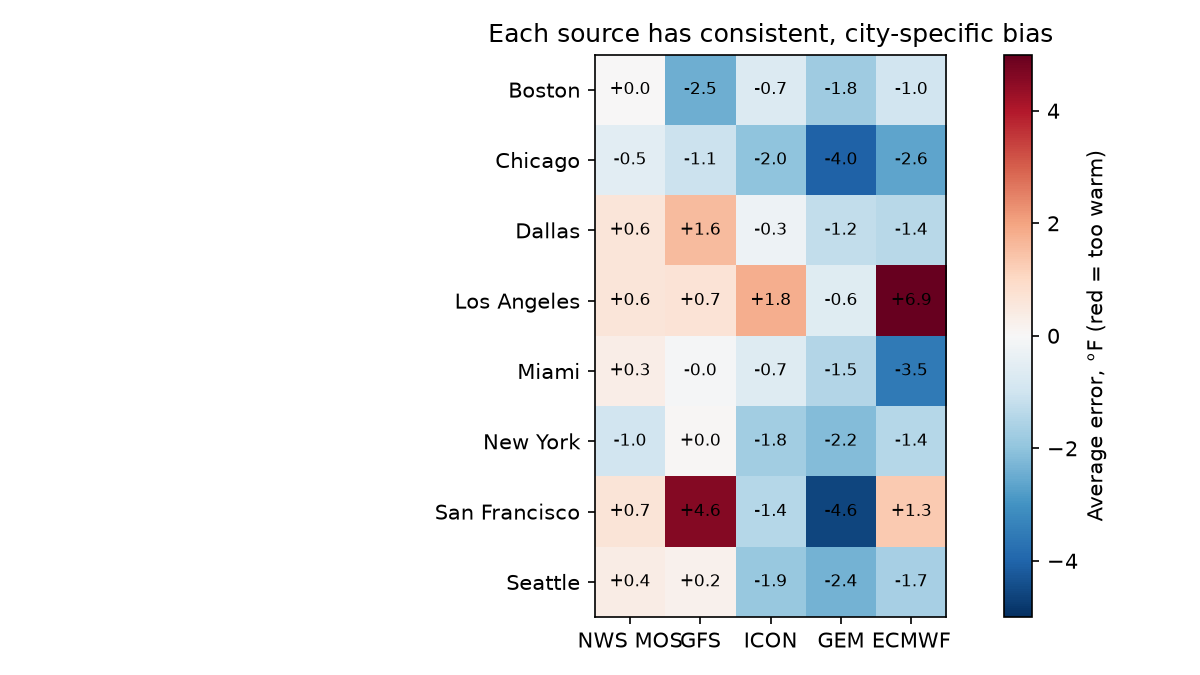

`eda_error_by_month.png`

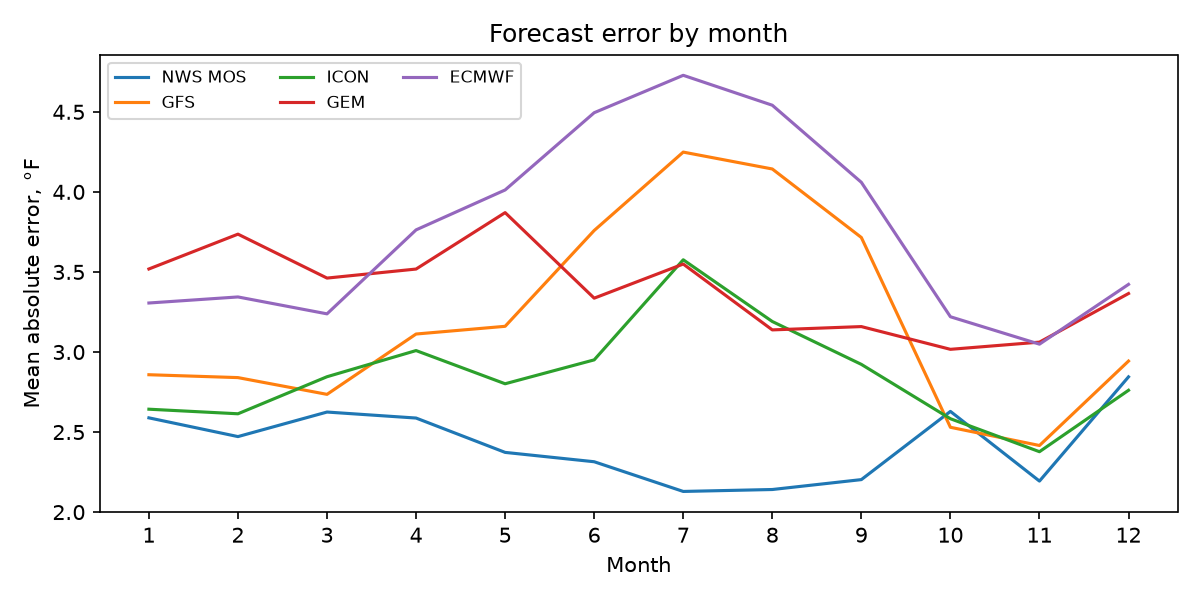

`eda_spread_vs_error.png`

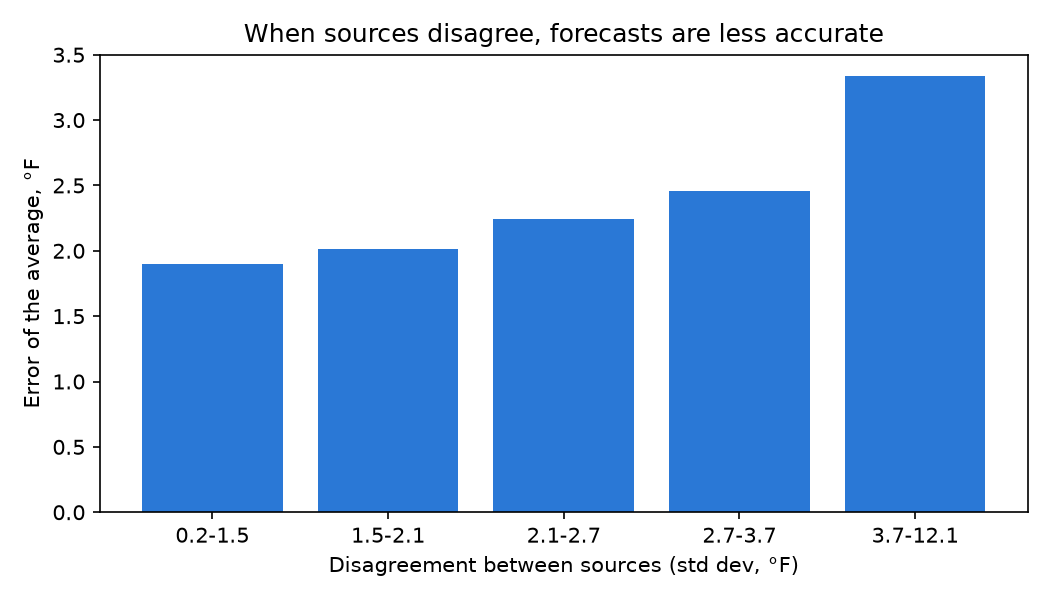

`test_mae_high.png`

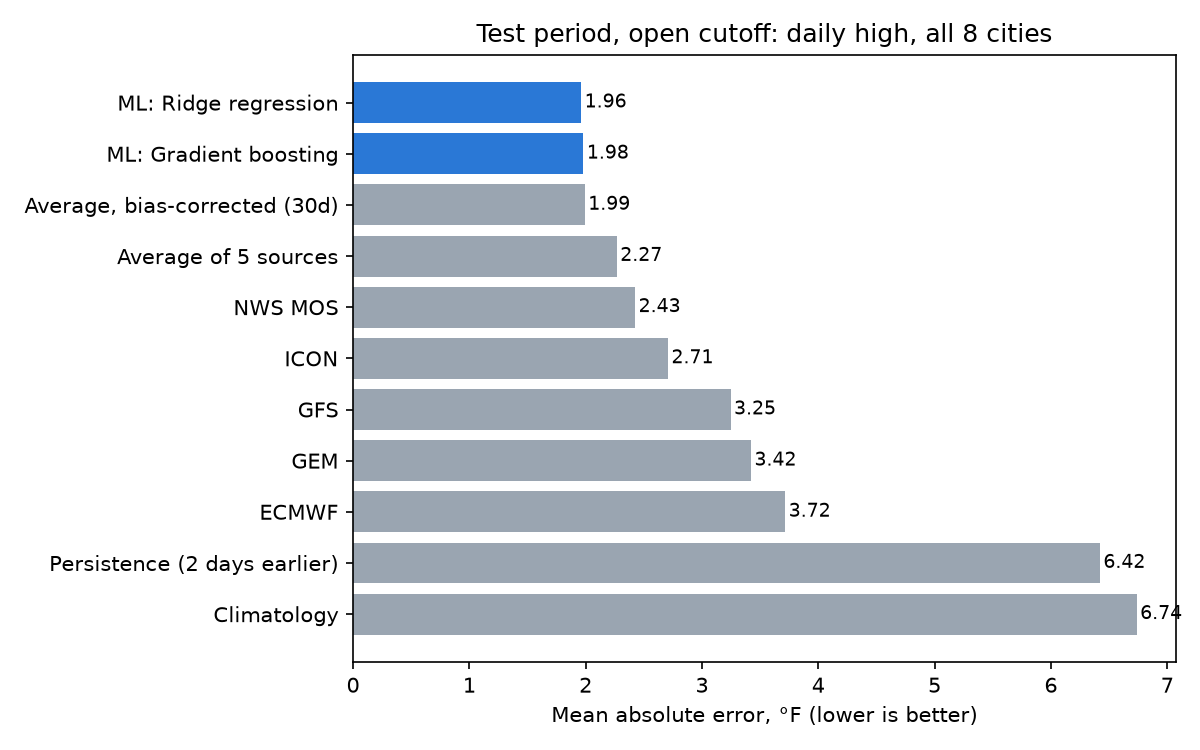

`test_mae_low.png`

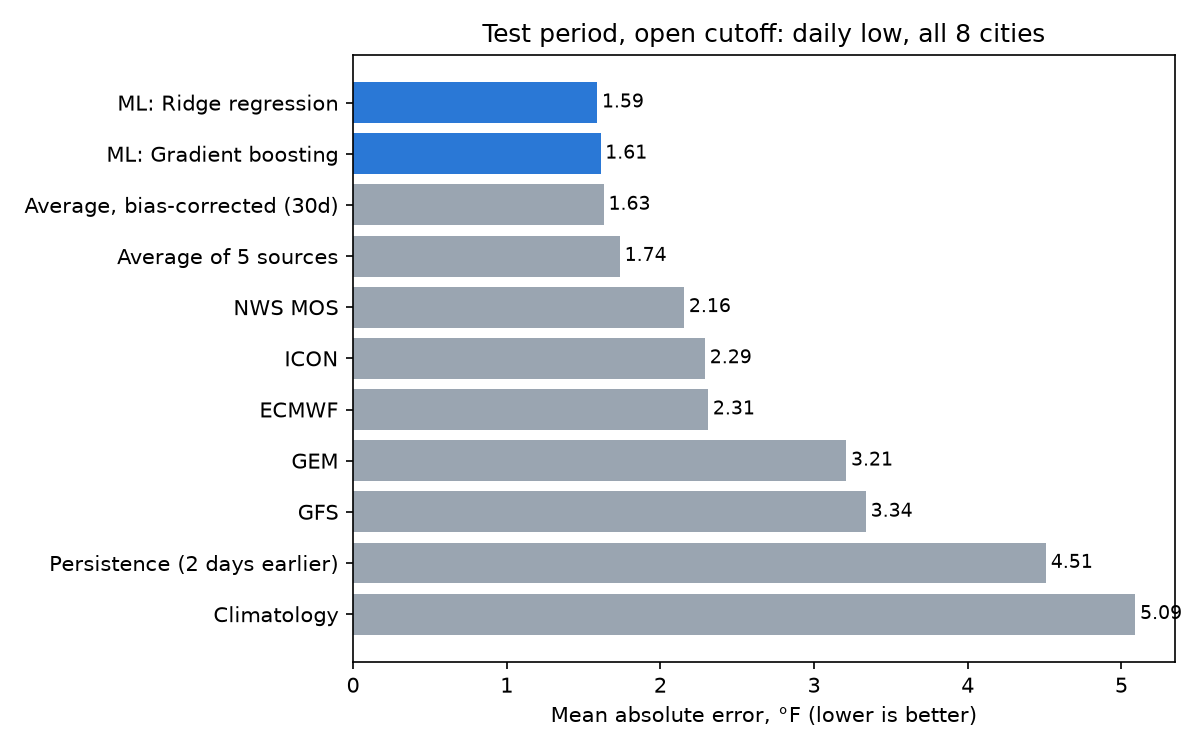

### midnight cutoff

`eda_bias_by_city.png`

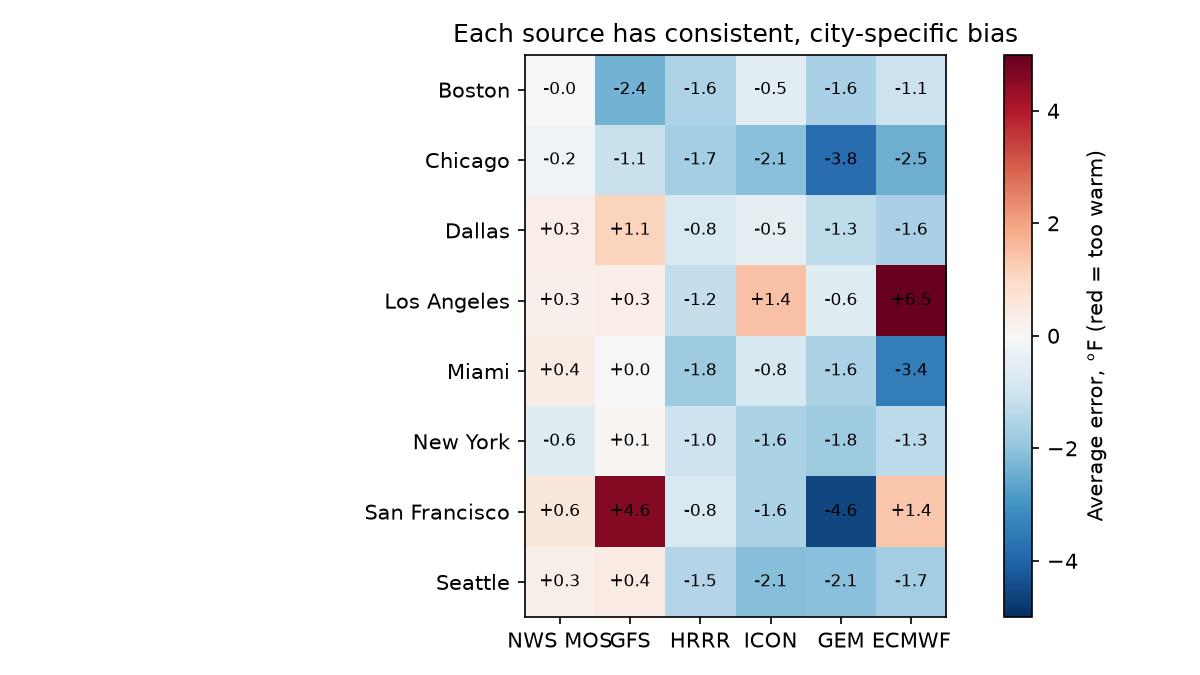

`eda_error_by_month.png`

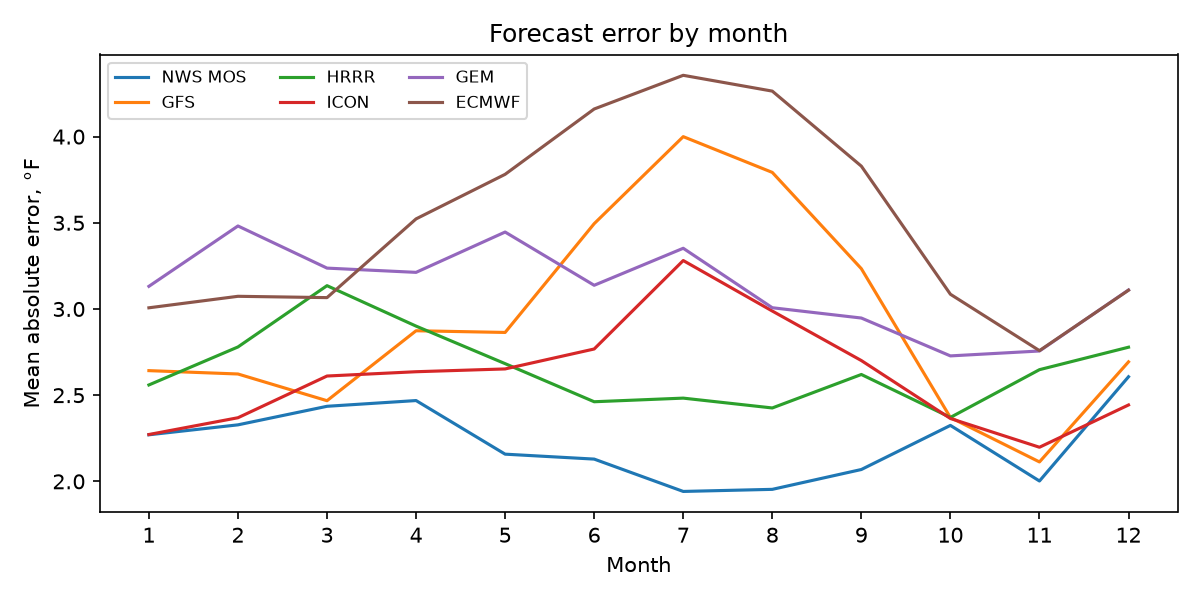

`eda_spread_vs_error.png`

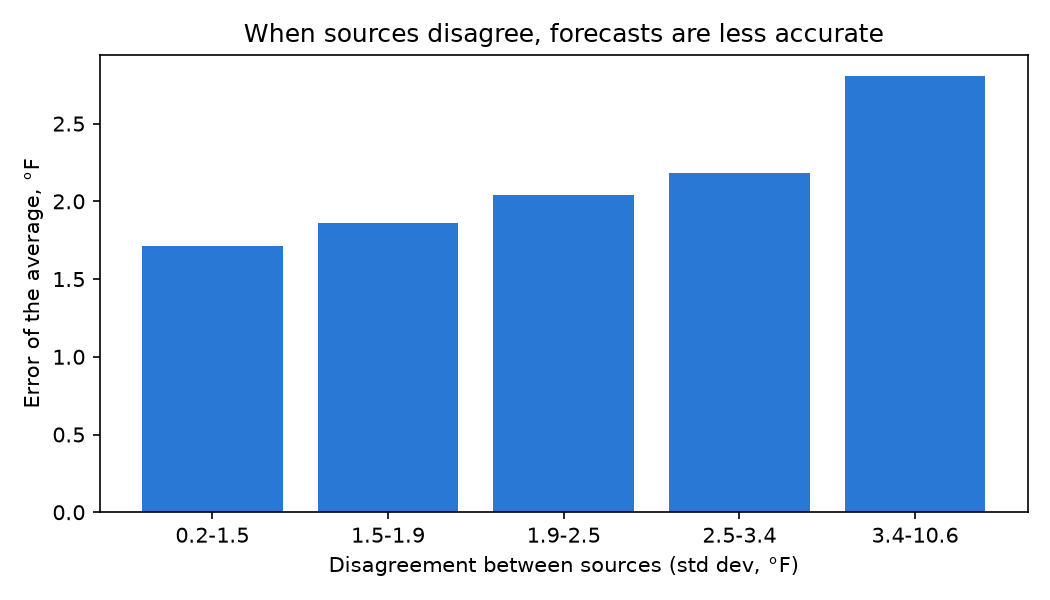

`test_mae_high.png`

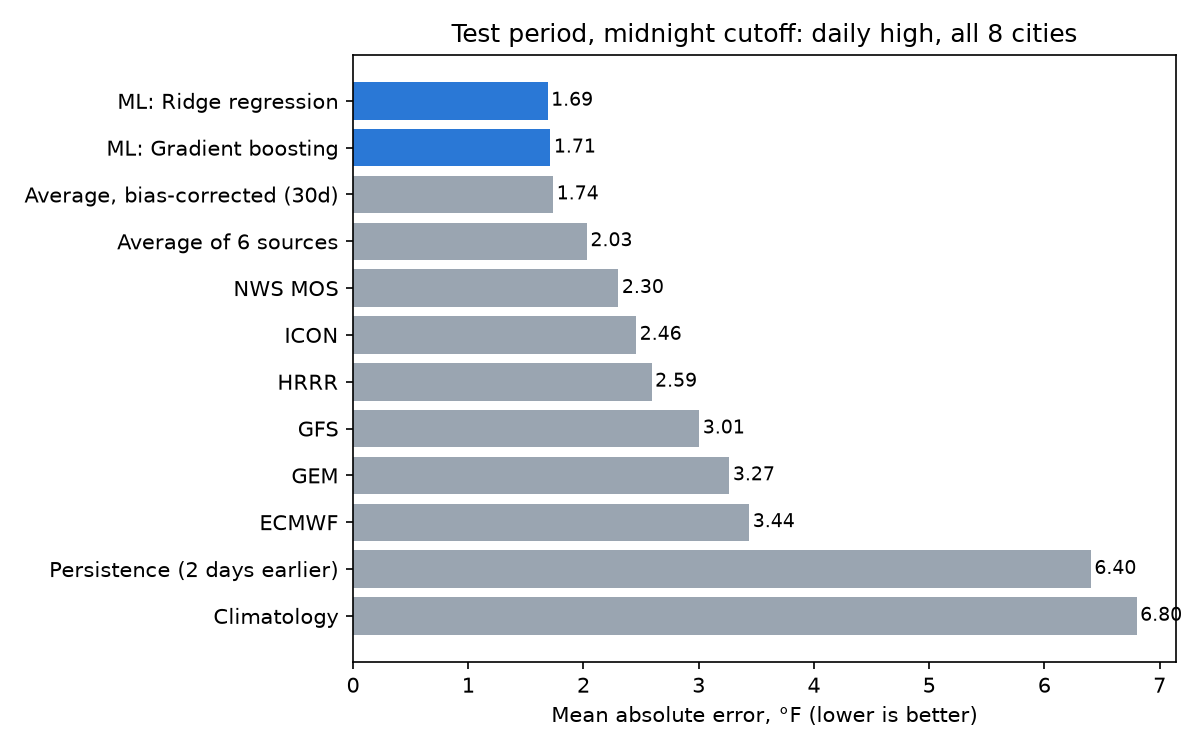

`test_mae_low.png`

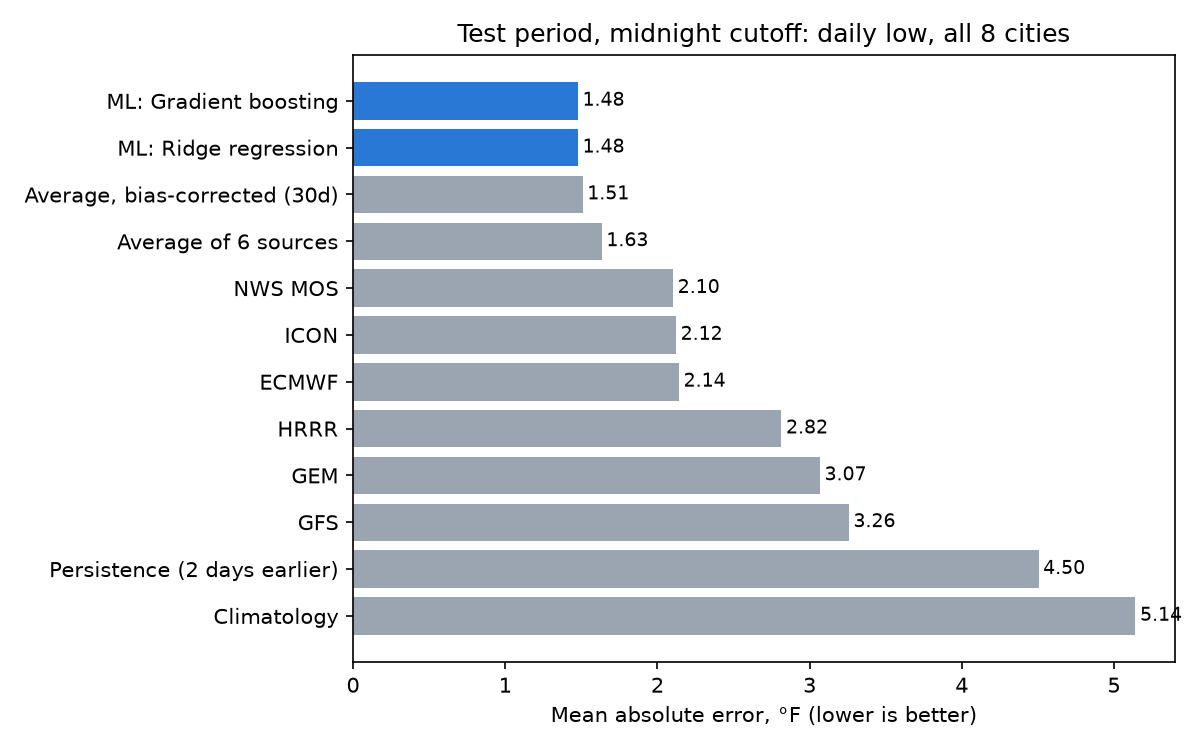

In [9]:
for c in CUTOFFS:
    display(Markdown(f'### {c} cutoff'))
    for png in sorted((OUTPUTS / c / 'figures').glob('*.png')):
        display(Markdown(f'`{png.name}`'), Image(filename=str(png), width=760))

## Kalshi comparison (daily highs)

Needs price snapshots: run `python src/backfill_prices.py --cutoff open` and `--cutoff midnight`, then set `RERUN = True` above.

In [10]:
for c in CUTOFFS:
    k = reports[c]['kalshi_high']
    if not k:
        print(f'{c}: no Kalshi prices yet -> python src/backfill_prices.py --cutoff {c}')
        continue
    display(Markdown(f"**{c} cutoff**: {k['events']:,} days, {k['markets']:,} brackets ({', '.join(k['cities'])})"))
    scores = {s: {key: v for key, v in k[s].items() if key != 'paper_trading'} for s in ('market', 'ridge', 'boost')}
    display(pd.DataFrame(scores).T.style.format('{:.3f}'))
    trading = {f: {key: v for key, v in k[f]['paper_trading'].items() if key != 'by_city'} for f in ('ridge', 'boost')}
    display(Markdown('Paper trading (buy YES at the ask when the model sees a 10-point edge; fees included):'),
            pd.DataFrame(trading).T)
    b = k['blend']
    display(Markdown(f"Blend: market weight **{b['market_weight']}**, chosen before {b['holdout_start']}; "
                     f"scored on {b['holdout_events']} later days"),
            pd.DataFrame({s: b[s] for s in ('market', 'model', 'blend')}).T.style.format('{:.3f}'))
    calibration = OUTPUTS / c / 'figures' / 'kalshi_calibration.png'
    if calibration.exists():
        display(Image(filename=str(calibration), width=560))

open: no Kalshi prices yet -> python src/backfill_prices.py --cutoff open
midnight: no Kalshi prices yet -> python src/backfill_prices.py --cutoff midnight
